# Sweep features

`sweep_features` computes the features of a whole sweep from its `Spikes`, like
`EphysSweepFeatureExtractor.sweep_feature` of the AllenSDK: features of the spike
train and of the subthreshold response. Units: s for `latency`, ms for the
interspike intervals and `tau`, Hz for `avg_rate`, mV for voltages. The examples use a cell from the [Allen Cell Types Database](https://celltypes.brain-map.org), loaded with a helper of this repository's tests. With your own recordings, all you need are NumPy arrays of time `t` (s), membrane potential `v` (mV) and, optionally, the injected current `i` (pA).

In [1]:
import sys
from pathlib import Path

import jax
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

jax.config.update("jax_enable_x64", True)  # float64: results match Allen exactly

# Recordings from the Allen Cell Types Database, as downloaded for the tests
# (uv run python tests/load_testdata.py), read with a helper of the test suite.
REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
sys.path.insert(0, str(REPO))

from jaxley_ephys import detect_spikes, sweep_features  # noqa: E402

In [2]:
from tests.utils.allen_dataset import load_specimen_case  # noqa: E402 (uses AllenSDK)

case = load_specimen_case(519832676, data_root=str(REPO / "tests/testdata/allen_cache"))

## A spiking sweep

`stimulus` tells `sweep_features` how to measure the stimulus amplitude `stim_amp`,
as Allen's cell extractor does (`"long_square"`, `"short_square"` or `"ramp"`).

In [3]:
number = case.records(kind="long_square", has_spikes=True)[-1].sweep_number
t, v, i, start, end = case.trace_for(number)
sp = detect_spikes(t, v, i, start, end)
features = sweep_features(sp, stimulus="long_square")
pd.Series({name: float(x) for name, x in features.items()})

adapt                     0.129420
avg_rate                  7.000140
first_isi                31.920000
isi_cv                    0.344335
latency                   0.056500
mean_isi                136.536667
median_isi              155.950000
min_deflect             -72.468750
min_deflect_i           230.000005
peak_deflect             44.718754
peak_deflect_index    53855.000000
sag                            NaN
stim_amp                230.000005
tau                            NaN
v_baseline              -72.451047
dtype: float64

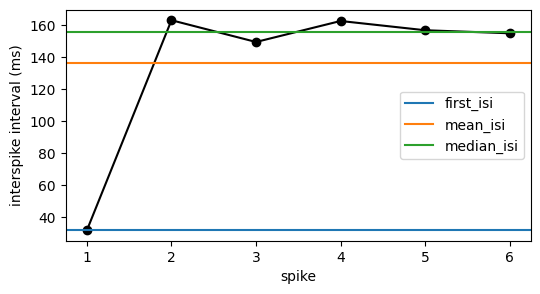

In [4]:
n = int(sp.n_spikes)
isi = 1e3 * np.diff(np.asarray(t[sp.threshold[:n]]))  # ms, like the ISI features
plt.figure(figsize=(6, 3))
plt.plot(np.arange(1, n), isi, "ko-")
for k, name in enumerate(["first_isi", "mean_isi", "median_isi"]):
    plt.axhline(features[name], color=f"C{k}", label=name)
plt.xlabel("spike")
plt.ylabel("interspike interval (ms)")
plt.legend()
plt.show()

## A hyperpolarizing sweep

For a negative current step, the subthreshold features describe the response:
the baseline before the step (`v_baseline`), the most negative voltage
(`peak_deflect`), the membrane time constant of an exponential fit to the drop
(`tau`) and how far the voltage relaxes back from its minimum (`sag`).

{'stim_amp': -110.0, 'v_baseline': -74.662, 'peak_deflect': -84.219, 'tau': 20.76, 'sag': 0.161}


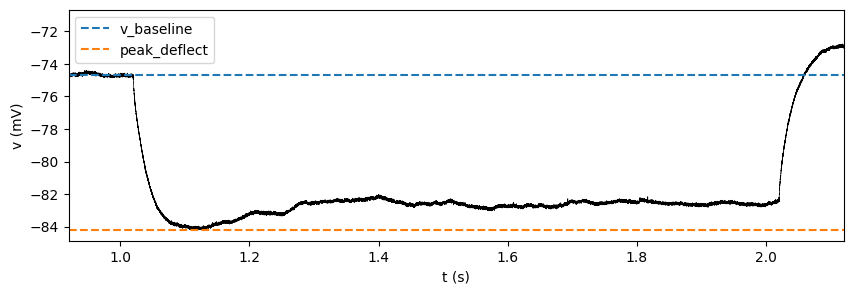

In [5]:
number = case.records(kind="long_square")[0].sweep_number  # the most negative step
t, v, i, start, end = case.trace_for(number)
features = sweep_features(detect_spikes(t, v, i, start, end), stimulus="long_square")
names = ["stim_amp", "v_baseline", "peak_deflect", "tau", "sag"]
print({name: round(float(features[name]), 3) for name in names})

plt.figure(figsize=(10, 3))
plt.plot(t, v, "k", lw=0.5)
plt.axhline(features["v_baseline"], color="C0", ls="--", label="v_baseline")
plt.axhline(features["peak_deflect"], color="C1", ls="--", label="peak_deflect")
plt.xlim(start - 0.1, end + 0.1)
plt.xlabel("t (s)")
plt.ylabel("v (mV)")
plt.legend()
plt.show()

Each feature is also available as a function of `jaxley_ephys.sweep`, e.g.
`sweep.tau(sp)` or `sweep.voltage_deflection(sp, "min")`.